# 토큰 비용 지연 비교

**이 노트북에서 할 일**

1. 요청 한 번의 사용량에서 입력·출력·캐시 입력 토큰 수를 읽고, 걸린 시간을 잽니다.
2. 공식 요금으로 예상 비용을 계산하는 함수를 만들고, 두 모델에 같은 메시지를 세 번씩 번갈아 보내 기록표에 모읍니다.
3. 긴 지시를 두 번 보내 캐시 입력을 확인하고, 기록을 Ch 7이 읽는 파일로 저장합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 읽는 데이터 파일은 없습니다.

인터넷 서비스의 모델 `gpt-5.4-mini`와 `gpt-5.4-nano`에 요청을 모두 9번 보냅니다. 모델별로는 mini에 6번, nano에 3번입니다.
실행 시간은 1분 안팎입니다. 예상 비용은 0.01달러 미만입니다(이 노트북 4절의 2026-09-17 공식 요금 기준).

마지막 셀은 실습 폴더의 `runs/provider-comparison-continuity.json` 파일을 새 기록으로 덮어씁니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
함께 설치되는 openai 패키지는 3.10.0이고, python-dotenv는 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

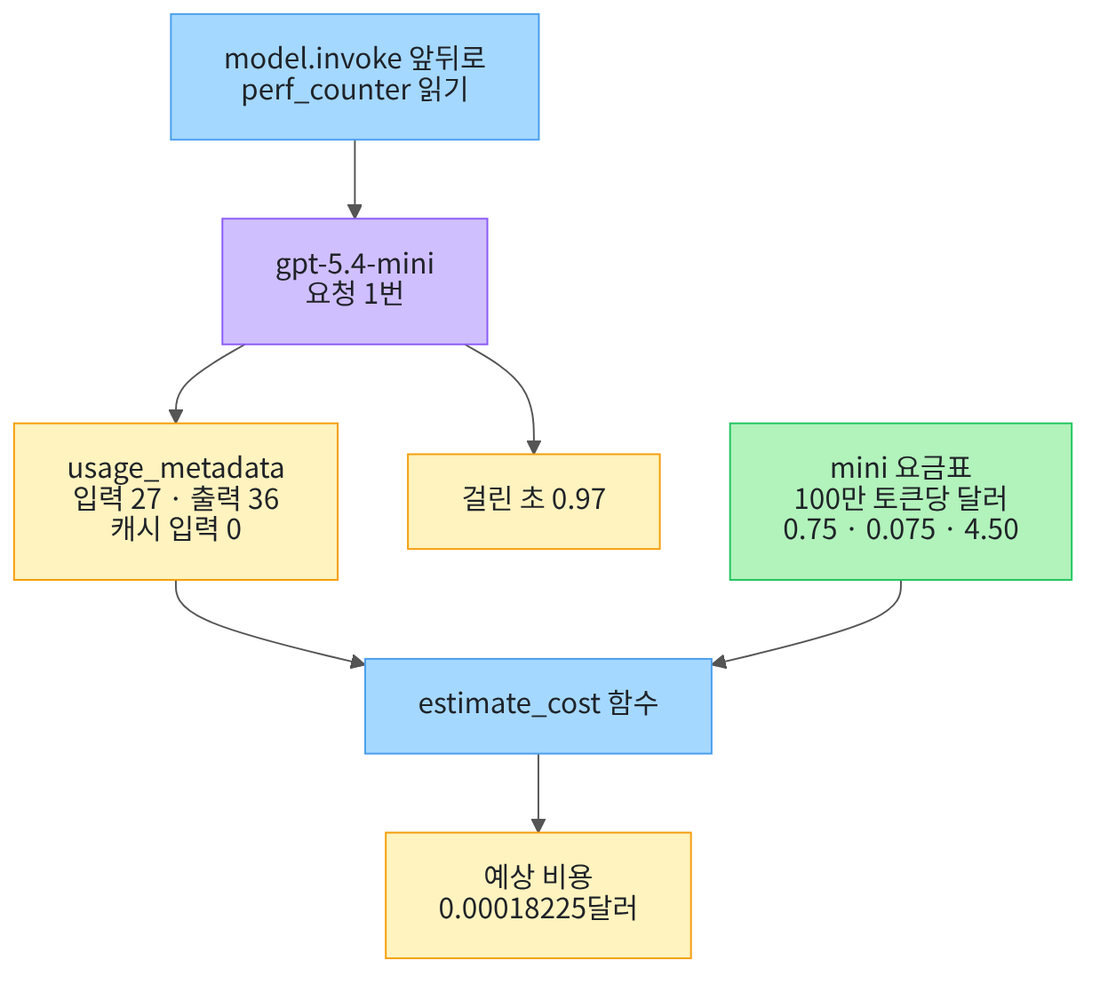

위에서 아래로 읽습니다. 초록 상자는 우리가 넣은 메시지와 요금표이고, 파란 상자는 코드 줄, 보라 상자는 실행한 모델입니다.
노란 상자는 출력으로 확인하는 값입니다. 토큰 수와 걸린 초는 응답에서, 예상 비용은 토큰 수와 요금표로 계산해서 얻습니다.

이 노트북은 요청 한 번을 이 흐름으로 기록표 한 줄에 담고, 같은 일을 두 모델에 세 번씩 되풀이합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
패키지 openai는 langchain-openai가 OpenAI 서버에 요청을 보낼 때 쓰는 패키지입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2


langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-openai: 1.6.0`, `openai: 3.10.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

01절과 같이 모델 객체를 만드는 함수를 불러옵니다. 걸린 시간을 재는 모듈 `time`은 05절에서 썼습니다.
모듈 `json`은 9절에서 기록을 JSON 글로 바꿀 때 씁니다. Ch 4 05절에서 `json.dumps()`로 딕셔너리를 JSON 글로 바꿨습니다.

In [2]:
# 걸린 시간을 재는 모듈, JSON 글을 다루는 모듈, 모델 객체를 만드는 함수를 불러옵니다
import json
import time

from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장, 토큰 수, 걸린 시간이 달라질 수 있습니다.
01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 메시지 목록 만들기

이번 절의 과제는 01절에서 받은 응답 객체 `AIMessage`의 역할을 설명하는 것입니다. system 지시는 02·04·05절의 「한 문장의 한국어로 답하세요.」를 다시 씁니다.
두 모델에 이 목록을 똑같이 보내므로, 목록은 한 번만 만듭니다.

실행 전에 예상합니다. 역할 이름 system과 user가 한 줄씩 나올 것입니다.

In [5]:
# 두 모델에 똑같이 보낼 지시와 과제를 튜플 목록에 담습니다
messages = [
    ("system", "한 문장의 한국어로 답하세요."),
    ("user", "AIMessage의 역할을 설명하세요."),
]
print("메시지 목록:")
for role, content in messages:
    print(role, "|", content)

메시지 목록:
system | 한 문장의 한국어로 답하세요.
user | AIMessage의 역할을 설명하세요.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `system | 한 문장의 한국어로 답하세요.`입니다. 둘째 줄은 `user | AIMessage의 역할을 설명하세요.`입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 3. 요청 한 번의 사용량과 걸린 시간

01절에서는 속성 `usage_metadata`에서 키 세 개를 꺼냈습니다. 이번에는 딕셔너리 전체를 출력해 안쪽 키까지 봅니다.
걸린 시간은 05절처럼 요청 앞뒤에서 `time.perf_counter()`를 읽어 뺍니다. 요청을 보내기 시작한 때부터 응답 객체를 받을 때까지의 시간입니다.

함수 `round(값, 2)`는 소수 둘째 자리까지 남깁니다. 05절의 걸린 초는 0.0처럼 짧은 값이 있어 둘째 자리까지 봅니다.

실행 전에 예상합니다. 사용량 딕셔너리에 01절의 세 키 말고 다른 키도 들어 있을 것입니다.

In [6]:
# 요청 한 번의 걸린 시간을 재고, 사용량 딕셔너리 전체를 봅니다(요청 1번)
start_time = time.perf_counter()
response = model.invoke(messages)
elapsed = time.perf_counter() - start_time
usage = response.usage_metadata
print("답:", response.text)
print("걸린 초:", round(elapsed, 2))
print("사용량:", usage)

답: AIMessage는 대화에서 AI가 생성한 응답 내용을 담아, 모델의 출력과 메타데이터를 구조적으로 표현하는 메시지입니다.
걸린 초: 0.97
사용량: {'input_tokens': 27, 'output_tokens': 36, 'total_tokens': 63, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}


**결과 읽기** — 출력 줄은 한 문장 답, `걸린 초: 0.97`, 사용량 딕셔너리입니다.
사용량 줄에는 `'input_tokens': 27`, `'output_tokens': 36`과 안쪽 딕셔너리 두 개가 보입니다.

안쪽 딕셔너리 `input_token_details`에는 `'cache_read': 0`이 있습니다. 캐시 입력 토큰 수라는 뜻이고, 이번 요청에서는 0이었습니다.

캐시 입력(cached input)은 제공자가 앞선 요청에서 처리해 둔 앞부분을 다시 쓴 입력 토큰입니다. 복사해 둔 서류를 다시 내면 새로 쓸 필요가 없는 것과 비슷합니다.
이 토큰은 일반 입력보다 싼 요금을 받습니다. 9절에서 캐시 입력이 0보다 큰 요청을 만들어 봅니다.

안쪽 딕셔너리 `output_token_details`의 `'reasoning': 0`은 모델이 답 전에 따로 쓴 추론 토큰 수입니다. 이번 요청은 `reasoning_effort="none"`이고, 이 값이 0이었습니다.

## 4. 요금표와 예상 비용 계산

요금은 모델마다 100만 토큰당 달러로 정해져 있습니다. 입력, 캐시 입력, 출력의 요금이 서로 다릅니다.
2026-09-17에 OpenAI 모델 페이지에서 확인한 값을 딕셔너리에 적습니다. 모델 mini는 입력 0.75, 캐시 입력 0.075, 출력 4.50달러입니다.

모델 nano는 입력 0.20, 캐시 입력 0.02, 출력 1.25달러입니다. 요금은 바뀔 수 있어 확인한 날짜를 함께 적습니다.
키 이름은 영어로 둡니다. Ch 7 08절 노트북이 이 이름으로 요금을 읽기 때문입니다.

실행 전에 예상합니다. 두 딕셔너리에 키가 세 개씩 보일 것입니다.

In [7]:
# 두 모델의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적습니다
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
nano_prices = {"ordinary_input": 0.20, "cached_input": 0.02, "output": 1.25}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)
print("nano 요금:", nano_prices)

요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}
nano 요금: {'ordinary_input': 0.2, 'cached_input': 0.02, 'output': 1.25}


**결과 읽기** — 출력 줄은 `요금 확인 날짜: 2026-09-17`, `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`, nano 요금 줄입니다.
숫자 4.50은 출력에서 `4.5`로 보입니다. 값은 같습니다.

예상 비용은 토큰 수에 요금을 곱해 더합니다. 먼저 입력 토큰에서 캐시 입력을 뺀 나머지를 일반 입력으로 봅니다.
식은 `(일반 입력 × 입력 요금 + 캐시 입력 × 캐시 요금 + 출력 × 출력 요금) ÷ 1000000`입니다. 요금이 100만 토큰당 값이라 마지막에 100만으로 나눕니다.

교재 예로 입력 100토큰 가운데 캐시 입력이 40, 출력이 10토큰이라고 합니다. mini 요금이면 `(60 × 0.75 + 40 × 0.075 + 10 × 4.50) ÷ 1000000`입니다.
괄호 안은 45 + 3 + 45 = 93이라, 예상 비용은 0.000093달러입니다.

아래 셀은 이 식을 함수 `estimate_cost()`로 정의합니다. 사용량이 `None`이면 비용도 `None`을 반환합니다. 04절에서 사용량을 끄면 `None`이었기 때문입니다.

사용량에 캐시 입력 키가 없으면 `get(키, 0)`으로 0을 씁니다. 할인을 빼고 모두 입력 요금으로 계산한다는 뜻입니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [8]:
# 사용량 딕셔너리와 세 요금으로 요청 한 번의 예상 비용(달러)을 계산하는 함수를 정의합니다
def estimate_cost(usage, input_rate, cached_input_rate, output_rate):
    if usage is None:
        return None
    # 캐시 입력 키가 없으면 할인 없이 모두 입력 요금으로 계산합니다
    details = usage.get("input_token_details", {})
    cache_read = details.get("cache_read", 0)
    normal_input = usage["input_tokens"] - cache_read
    input_cost = normal_input * input_rate + cache_read * cached_input_rate
    output_cost = usage["output_tokens"] * output_rate
    price_unit = 1000000
    return (input_cost + output_cost) / price_unit

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이제 함수 `estimate_cost()`를 쓸 수 있습니다.

함수가 앞의 교재 예와 같은 값을 내는지 먼저 확인합니다. 사용량이 없는 경우도 함께 넣어 봅니다.
출력의 `9.3e-05`는 0.000093을 짧게 적은 모양입니다. 끝의 `e-05`는 소수점을 왼쪽으로 다섯 칸 옮긴다는 뜻입니다.

실행 전에 예상합니다. 교재 예는 0.000093달러, 사용량이 없으면 `None`일 것입니다.

In [9]:
# 교재 예 사용량과, 사용량이 없는 경우로 함수를 확인합니다(요청 없음)
example_usage = {
    "input_tokens": 100,
    "output_tokens": 10,
    "input_token_details": {"cache_read": 40},
}
example_cost = estimate_cost(
    example_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
missing_cost = estimate_cost(
    None, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
print("교재 예 비용(달러):", example_cost)
print("사용량이 없을 때 비용:", missing_cost)
assert round(example_cost, 6) == 0.000093

교재 예 비용(달러): 9.3e-05
사용량이 없을 때 비용: None


**결과 읽기** — 출력 줄은 `교재 예 비용(달러): 9.3e-05`와 `사용량이 없을 때 비용: None`입니다. `assert`도 통과했습니다.
함수가 캐시 입력 40을 싼 요금으로 나눠 계산했습니다. 모르는 사용량은 0달러가 아니라 `None`으로 남았습니다.

이제 3절에서 받은 실제 사용량으로 계산합니다. 한 요청의 비용은 아주 작은 수라, 같은 요청을 1,000번 보낼 때의 비용도 함께 봅니다.

실행 전에 예상합니다. 캐시 입력이 0이므로, 입력 토큰은 모두 입력 요금으로 계산될 것입니다.

In [10]:
# 3절 요청의 실제 사용량으로 mini 요금 기준 예상 비용을 계산합니다
cost = estimate_cost(
    usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"]
)
request_count = 1000
print("예상 비용(달러):", cost)
print("같은 요청 1,000번의 예상 비용(달러):", round(cost * request_count, 4))

예상 비용(달러): 0.00018225
같은 요청 1,000번의 예상 비용(달러): 0.1823


**결과 읽기** — 출력 줄은 `예상 비용(달러): 0.00018225`와 `같은 요청 1,000번의 예상 비용(달러): 0.1823`입니다.
입력 27토큰보다 출력 36토큰의 비용이 훨씬 컸습니다. 출력 요금이 입력 요금의 6배이기 때문입니다.

이 값은 요금표로 계산한 예상 비용이고, 실제 청구 금액을 확인한 것은 아닙니다.

## 5. 두 모델을 같은 조건으로 준비

비교할 때는 모델 이름 말고 나머지 조건을 같게 둡니다. 메시지 목록은 2절의 `messages` 하나를 두 모델에 보냅니다.
설정은 temperature 0, 출력 상한(`max_tokens`) 180, 기다리는 시간 30초로 같게 둡니다. 출력 상한은 01절 7절에서 배운 값입니다.

다시 시도 횟수는 `max_retries=0`으로 끕니다. 05절 6절에서 다시 시도를 적지 않자, 기다린 시간이 걸린 시간에 들어갔습니다.
그러면 요청 한 번과 기록표 한 줄이 맞지 않게 됩니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 두 모델의 출력 상한이 같은 값으로 보일 것입니다.

In [11]:
# 설정이 같고 모델 이름만 다른 두 모델 객체와 후보 목록을 만듭니다(요청 없음)
mini_model = init_chat_model(
    "openai:gpt-5.4-mini", temperature=0, reasoning_effort="none",
    max_tokens=180, timeout=30, max_retries=0,
)
nano_model = init_chat_model(
    "openai:gpt-5.4-nano", temperature=0, reasoning_effort="none",
    max_tokens=180, timeout=30, max_retries=0,
)
# (기록할 모델 이름, 모델 객체, 요금표) 세 칸 튜플을 목록에 담습니다
candidates = [
    ("openai:gpt-5.4-mini", mini_model, mini_prices),
    ("openai:gpt-5.4-nano", nano_model, nano_prices),
]
print("후보 수:", len(candidates))
print("출력 상한(max_tokens):", mini_model.max_tokens, nano_model.max_tokens)

후보 수: 2
출력 상한(max_tokens): 180 180


**결과 읽기** — 출력 줄은 `후보 수: 2`와 `출력 상한(max_tokens): 180 180`입니다. 두 모델의 조건이 같게 준비되었습니다.

## 6. 요청 한 번을 기록표 한 줄로

같은 일을 여러 번 하므로 함수 두 개로 나눕니다. 첫 함수 `timed_invoke()`는 요청을 보내면서 걸린 시간을 잽니다.
응답 객체와 걸린 초를 튜플로 반환합니다. Ch 5 08절에서 함수가 튜플을 반환하고, 부르는 쪽에서 두 이름에 풀어 담았습니다.

이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [12]:
# 모델 객체로 메시지 목록을 보내고, 응답 객체와 걸린 초를 튜플로 반환하는 함수를 정의합니다
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_cost_record()`는 응답 객체와 걸린 초를 딕셔너리 한 줄로 만듭니다. 02절 기록표처럼 한 줄에 한 요청을 적습니다.
05절 10절처럼 응답 메타데이터의 `model_name`으로 응답한 모델도 적습니다. 답 문장도 함께 적습니다. 토큰 수와 시간이 어떤 답에서 나왔는지 나중에 읽기 위해서입니다.

이 함수는 이번 OpenAI 응답처럼 캐시 입력 키가 있다고 보고 바로 꺼냅니다. 키가 없는 응답이면 여기서 오류가 납니다.

이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [13]:
# 응답 객체·걸린 초·요금표로 기록표 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_cost_record(model_id, run_response, run_elapsed, prices):
    run_usage = run_response.usage_metadata
    run_cost = estimate_cost(run_usage, prices["ordinary_input"], prices["cached_input"], prices["output"])
    record = {
        "모델": model_id,
        "응답한 모델": run_response.response_metadata["model_name"],
        "답": run_response.text,
        "입력 토큰 수": run_usage["input_tokens"],
        "캐시 입력 토큰 수": run_usage["input_token_details"]["cache_read"],
        "출력 토큰 수": run_usage["output_tokens"],
        "끝난 이유": run_response.response_metadata["finish_reason"],
        "걸린 초": round(run_elapsed, 2),
        "예상 비용(달러)": run_cost,
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이제 두 함수를 반복문 안에서 부릅니다.

한 모델을 세 번 연달아 보내지 않고, mini와 nano를 번갈아 보냅니다. 네트워크 사정이 잠깐 나빠지면 한 모델의 기록만 늦어지는 일을 줄이려는 것입니다.
바깥 반복은 `range(3)`으로 세 번, 안쪽 반복은 후보 목록의 세 칸 튜플을 세 이름에 풀어 담습니다. 세 칸 풀어 담기는 Ch 5에서 썼습니다.

실행 전에 예상합니다. 요청 6번에 기록표는 6줄일 것입니다.

In [14]:
# 두 모델에 같은 메시지를 번갈아 세 번씩 보내고 기록표에 한 줄씩 담습니다(요청 6번)
repeat_count = 3
records = []
for round_number in range(repeat_count):
    for model_id, run_model, prices in candidates:
        sent_response, sent_seconds = timed_invoke(run_model, messages)
        record = make_cost_record(model_id, sent_response, sent_seconds, prices)
        records.append(record)
print("기록한 줄 수:", len(records))
assert len(records) == 6

기록한 줄 수: 6


**결과 읽기** — 출력 줄은 `기록한 줄 수: 6`입니다. `assert`도 통과했습니다.
요청 수는 코드가 정한 값이라 매번 같습니다. 토큰 수와 걸린 초는 실행마다 달라질 수 있어 `assert`로 확인하지 않습니다.

## 7. 기록표 읽기

기록표를 한 줄에 한 요청씩 출력합니다. 비용은 1,000번 보낼 때의 달러로 바꿔 보여 줍니다.
답 문장은 길어서 이 표에 넣지 않고, 다음 셀에서 따로 봅니다.

실행 전에 예상합니다. 입력 토큰 수는 같은 메시지라 모든 줄이 같고, 출력 토큰 수와 걸린 초는 줄마다 다를 것입니다.

In [15]:
# 기록표를 모델 | 입력 | 캐시 입력 | 출력 | 끝난 이유 | 걸린 초 | 1,000번 비용 모양으로 출력합니다
print("기록표(모델 | 입력 | 캐시 입력 | 출력 | 끝난 이유 | 걸린 초 | 1,000번 비용):")
for record in records:
    thousand_cost = round(record["예상 비용(달러)"] * request_count, 4)
    print(
        record["모델"], "|", record["입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|",
        record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"], "|", thousand_cost,
    )

기록표(모델 | 입력 | 캐시 입력 | 출력 | 끝난 이유 | 걸린 초 | 1,000번 비용):
openai:gpt-5.4-mini | 27 | 0 | 36 | stop | 1.1 | 0.1823
openai:gpt-5.4-nano | 27 | 0 | 41 | stop | 0.71 | 0.0566
openai:gpt-5.4-mini | 27 | 0 | 43 | stop | 0.8 | 0.2137
openai:gpt-5.4-nano | 27 | 0 | 40 | stop | 0.98 | 0.0554
openai:gpt-5.4-mini | 27 | 0 | 57 | stop | 1.16 | 0.2767
openai:gpt-5.4-nano | 27 | 0 | 39 | stop | 0.67 | 0.0542


**결과 읽기** — 라벨 줄 아래 여섯 줄이 mini와 nano 차례로 번갈아 나옵니다. 첫 줄은 `openai:gpt-5.4-mini | 27 | 0 | 36 | stop | 1.1 | 0.1823`입니다.
입력 토큰 수는 여섯 줄 모두 27이고, 캐시 입력은 모두 0, 끝난 이유는 모두 stop이었습니다.

출력 토큰 수는 mini가 36·43·57, nano가 41·40·39였습니다. 같은 모델에 같은 메시지를 보냈지만 답의 길이가 요청마다 달랐습니다.
1,000번 비용은 mini가 0.1823~0.2767달러, nano가 0.0542~0.0566달러였습니다. 출력 토큰이 많은 줄일수록 비용이 컸습니다.
걸린 초도 같은 모델에서 줄마다 달랐습니다.

## 8. 실험 결과 해석 — 모델마다 모아 보기

한 번 잰 시간은 우연히 빠르거나 느릴 수 있습니다. 그래서 모델마다 세 번의 걸린 초를 모아 가운데 값을 봅니다.

가운데 값(median)은 값을 크기 순서로 늘어놓았을 때 한가운데 있는 값입니다. 세 사람 키를 줄 세우면 둘째 사람의 키입니다.
이 셀에서는 `sorted()`로 정렬한 목록의 가운데 자리 `int(len(ordered) / 2)`에서 꺼냅니다. 세 개면 1번 자리입니다.

집합 `set()`에 답 문장을 넣어 서로 다른 답이 몇 개인지도 셉니다. Ch 5 06절에서 같은 방법으로 답의 종류를 셌습니다.

실행 전에 예상합니다. temperature 0이라도 서로 다른 답이 1개보다 많은 모델이 있을 수 있습니다.

In [16]:
# 모델마다 걸린 초를 모아 가운데 값을 찾고, 서로 다른 답 수와 세 번의 비용 합을 봅니다
for model_id, run_model, prices in candidates:
    seconds = []
    answers = set()
    total_cost = 0
    for record in records:
        if record["모델"] == model_id:
            seconds.append(record["걸린 초"])
            answers.add(record["답"])
            total_cost = total_cost + record["예상 비용(달러)"]
    ordered = sorted(seconds)
    middle = ordered[int(len(ordered) / 2)]
    print(model_id, "| 걸린 초:", seconds, "| 가운데 값:", middle)
    print(model_id, "| 서로 다른 답 수:", len(answers), "| 세 번 비용 합(달러):", round(total_cost, 6))

openai:gpt-5.4-mini | 걸린 초: [1.1, 0.8, 1.16] | 가운데 값: 1.1
openai:gpt-5.4-mini | 서로 다른 답 수: 3 | 세 번 비용 합(달러): 0.000673
openai:gpt-5.4-nano | 걸린 초: [0.71, 0.98, 0.67] | 가운데 값: 0.71
openai:gpt-5.4-nano | 서로 다른 답 수: 3 | 세 번 비용 합(달러): 0.000166


**결과 읽기** — 출력은 모델마다 두 줄입니다. mini 첫 줄은 `openai:gpt-5.4-mini | 걸린 초: [1.1, 0.8, 1.16] | 가운데 값: 1.1`입니다.
nano 첫 줄은 `openai:gpt-5.4-nano | 걸린 초: [0.71, 0.98, 0.67] | 가운데 값: 0.71`입니다.
서로 다른 답 수는 두 모델 모두 `3`이었습니다. 세 번 비용 합은 mini `0.000673`, nano `0.000166`달러였습니다.

temperature 0이었지만 두 모델 모두 세 답이 서로 달랐습니다. 01절에 적은 대로, 매번 같은 답을 보장하지는 않습니다.

이번 실행에서는 nano의 걸린 초 가운데 값이 mini보다 작았고, 비용도 작았습니다. 다만 요청은 모델마다 세 번, 과제는 하나였습니다.
이 기록으로 nano가 늘 빠르다거나 더 좋은 모델이라고 말할 수 없습니다. 답이 과제를 잘 풀었는지는 토큰 수와 시간으로 알 수 없어, 답 문장을 따로 읽어야 합니다.

## 9. 값 바꿔 보기 — 긴 지시를 두 번 보내기

바꾸는 값은 system 지시 하나입니다. 같은 규칙 문장을 80번 이어 붙여 긴 지시를 만듭니다. user 과제는 2절의 `messages[1]`을 그대로 씁니다.
OpenAI 프롬프트 캐싱 안내는, 앞부분 전체가 앞선 요청과 같아야 캐시를 다시 쓸 수 있다고 적습니다.

그래서 지시 맨 앞에 지금 시각을 붙입니다. 노트북을 다시 실행해도 첫 요청의 앞부분이 이전 실행과 달라집니다.
함수 `time.strftime(모양)`은 지금 시각을 모양대로 적은 글을 반환합니다. 모양 글 `%Y%m%dT%H%M%S`는 연월일, 문자 T, 시분초 순서입니다.

실행 전에 예상합니다. 긴 지시의 글자 수가 3,000자보다 많을 것입니다.

In [17]:
# 지금 시각을 맨 앞에 두고 같은 규칙 문장을 80번 이어 붙여 긴 system 지시를 만듭니다(요청 없음)
rule_sentence = "상담 답변에는 확인한 사실만 적고, 확인하지 못한 내용은 확인하지 못했다고 적습니다. "
rule_count = 80
long_system = "작성 시각 " + time.strftime("%Y%m%dT%H%M%S") + ". "
for number in range(rule_count):
    long_system = long_system + rule_sentence
long_system = long_system + "한 문장의 한국어로 답하세요."
long_messages = [("system", long_system), messages[1]]
print("긴 지시의 글자 수:", len(long_system))
print("user 메시지:", long_messages[1])

긴 지시의 글자 수: 3879
user 메시지: ('user', 'AIMessage의 역할을 설명하세요.')


**결과 읽기** — 출력 줄은 `긴 지시의 글자 수: 3879`와 `user 메시지: ('user', 'AIMessage의 역할을 설명하세요.')`입니다.
지시만 길어졌고, 과제는 2절과 같습니다.

이 긴 메시지 목록을 mini 모델에 두 번 연달아 보냅니다. 두 번째 요청은 앞부분이 첫 요청과 같습니다.
6절의 두 함수로 기록표 줄을 만들고 7절과 같은 모양으로 출력합니다. 비용은 1,000번으로 바꾸지 않고 한 요청의 달러로 봅니다.

실행 전에 예상합니다. 첫 줄의 캐시 입력은 0이고, 둘째 줄에서는 0보다 클 것입니다.

In [18]:
# 긴 지시 메시지를 mini 모델로 두 번 연달아 보내고, 기록표 두 줄을 출력합니다(요청 2번)
send_count = 2
cache_records = []
for number in range(send_count):
    sent_response, sent_seconds = timed_invoke(mini_model, long_messages)
    record = make_cost_record("openai:gpt-5.4-mini", sent_response, sent_seconds, mini_prices)
    cache_records.append(record)
print("긴 지시 기록표(입력 | 캐시 입력 | 출력 | 걸린 초 | 예상 비용):")
for record in cache_records:
    print(
        record["입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|", record["출력 토큰 수"], "|",
        record["걸린 초"], "|", record["예상 비용(달러)"],
    )

긴 지시 기록표(입력 | 캐시 입력 | 출력 | 걸린 초 | 예상 비용):
1958 | 0 | 37 | 0.88 | 0.001635
1958 | 1792 | 37 | 0.93 | 0.0004254


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1958 | 0 | 37 | 0.88 | 0.001635`, 둘째 줄은 `1958 | 1792 | 37 | 0.93 | 0.0004254`입니다.
두 요청의 입력 토큰 수는 같았고, 둘째 요청은 그 가운데 1792토큰이 캐시 입력이었습니다.

둘째 요청의 비용이 첫 요청보다 작았습니다. 이번에는 출력 토큰 수도 37로 같았지만, 실행마다 달라질 수 있습니다. 그래서 캐시 할인만의 차이를 따로 계산해 봅니다.
둘째 요청의 사용량을 캐시 요금 대신 입력 요금으로 한 번 더 계산합니다. 반복문이 끝난 뒤 `sent_response`에는 마지막인 둘째 응답이 남아 있습니다.

실행 전에 예상합니다. 할인 없이 계산한 값이 둘째 줄 비용보다 클 것입니다.

In [19]:
# 둘째 요청을 캐시 할인 없이 계산한 비용과 나란히 봅니다(요청 없음)
second_usage = sent_response.usage_metadata
no_discount_cost = estimate_cost(
    second_usage, mini_prices["ordinary_input"], mini_prices["ordinary_input"], mini_prices["output"]
)
second_cost = cache_records[1]["예상 비용(달러)"]
same_input = cache_records[0]["입력 토큰 수"] == cache_records[1]["입력 토큰 수"]
print("둘째 요청 예상 비용(달러):", second_cost)
print("캐시 할인 없이 계산한 비용(달러):", no_discount_cost)
print("두 요청의 입력 토큰 수가 같은가:", same_input)
assert same_input

둘째 요청 예상 비용(달러): 0.0004254
캐시 할인 없이 계산한 비용(달러): 0.001635
두 요청의 입력 토큰 수가 같은가: True


**결과 읽기** — 출력 줄은 `둘째 요청 예상 비용(달러): 0.0004254`, `캐시 할인 없이 계산한 비용(달러): 0.001635`, `두 요청의 입력 토큰 수가 같은가: True`입니다.
같은 사용량에서 캐시 할인만 빼니 비용이 약 3.8배로 커졌습니다. 이 값은 첫 요청의 비용과 같았습니다. 두 요청의 출력 토큰 수가 같았기 때문입니다.

캐시 입력이 생길지는 요청을 보내 봐야 압니다. 짧은 3·6절 요청은 모두 0이었고, 이번 긴 지시도 첫 요청은 0이었습니다.
교재를 만들 때 규칙 문장을 50번만 이어 붙인 지시(약 1,250토큰)는 두 번째 요청도 캐시 입력이 0이었습니다. 그래서 이 노트북은 80번으로 정했습니다.

## 10. 기록을 파일로 남기기

기록표는 노트북을 닫으면 사라집니다. 그래서 실행 조건과 요금표, 기록표를 JSON 파일 하나에 저장합니다.
Ch 7 08절 노트북이 이 파일을 읽어, 앞 실행의 이름 `run_id`와 요금을 확인합니다. 그래서 키 이름은 그 노트북이 읽는 이름을 씁니다.

실행 이름은 `ch06-provider-`와 지금 시각을 이어 붙여 만듭니다. 글 두 개를 `+`로 이으면 하나의 글이 됩니다.

실행 전에 예상합니다. 실행 이름이 `ch06-provider-`로 시작할 것입니다.

In [20]:
# 실행 이름·조건·요금표·기록표를 딕셔너리 하나에 모읍니다(9절 긴 지시 기록은 넣지 않습니다)
run_id = "ch06-provider-" + time.strftime("%Y%m%dT%H%M%S")
conditions = {"repetitions": repeat_count, "max_tokens": 180, "max_retries": 0, "messages": messages}
pricing = {"date": pricing_date, "unit": "USD per 1M tokens", "openai": mini_prices, "openai_nano": nano_prices}
run_record = {
    "run_id": run_id,
    "run_date": time.strftime("%Y-%m-%d"),
    "source_chapter": "ch06",
    "conditions": conditions,
    "pricing": pricing,
    "records": records,
}
print("실행 이름:", run_id)
print("담은 기록표 줄 수:", len(run_record["records"]))

실행 이름: ch06-provider-20260917T020433
담은 기록표 줄 수: 6


**결과 읽기** — 출력 줄은 `실행 이름: ch06-provider-20260917T020433`처럼 시각이 붙은 이름과 `담은 기록표 줄 수: 6`입니다.
요금표의 키 `openai`에는 mini 요금을 담았습니다. Ch 7 08절이 이 키로 mini 요금을 읽기 때문입니다. 기록표 줄의 키는 한국어이고, Ch 7 08절은 이 줄을 읽지 않습니다.

파일은 실습 폴더의 `runs` 폴더에 씁니다. 노트북을 `notebooks` 폴더에서 열면 `runs` 폴더는 한 칸 위에 있어 `../runs`로 적습니다.
함수 `os.path.exists()`는 경로 글자를 받아, 그 파일이나 폴더가 있으면 `True`를 반환합니다. 그 폴더가 없으면 프로젝트 맨 위 폴더에서 연 경우로 보고 긴 경로를 씁니다. Ch 5 01절 준비 셀과 같은 방법입니다.

함수 `json.dumps()`의 인자 `ensure_ascii=False`는 한글을 그대로 둡니다. 인자 `indent=2`는 안쪽을 두 칸씩 들여 씁니다. 두 인자는 Ch 4 05절에서 썼습니다.
쓴 파일을 다시 읽어 실행 이름이 같은지 확인합니다.

실행 전에 예상합니다. 다시 읽은 실행 이름이 위 셀과 같고, 기록표는 6줄일 것입니다.

In [21]:
# runs 폴더의 JSON 파일에 기록을 쓰고, 다시 읽어 확인합니다
record_path = "../runs/provider-comparison-continuity.json"
if not os.path.exists("../runs"):
    record_path = "labs/part2/ch06-langchain-start/runs/provider-comparison-continuity.json"
payload = json.dumps(run_record, ensure_ascii=False, indent=2)
with open(record_path, "w", encoding="utf-8") as file:
    file.write(payload)
with open(record_path, encoding="utf-8") as file:
    saved = json.loads(file.read())
print("다시 읽은 실행 이름이 같은가:", saved["run_id"] == run_id)
print("다시 읽은 기록표 줄 수:", len(saved["records"]))
assert saved["run_id"] == run_id

다시 읽은 실행 이름이 같은가: True
다시 읽은 기록표 줄 수: 6


**결과 읽기** — 출력 줄은 `다시 읽은 실행 이름이 같은가: True`와 `다시 읽은 기록표 줄 수: 6`입니다. `assert`도 통과했습니다.
파일 경로는 컴퓨터마다 달라서 출력하지 않았습니다. 이 노트북을 다시 실행하면 파일은 새 기록으로 바뀝니다.

## 정리

- 사용량 딕셔너리에서 입력·출력 토큰 수와 캐시 입력 토큰 수를 읽고, 요금표로 예상 비용을 계산했습니다.
- 같은 메시지를 두 모델에 세 번씩 번갈아 보내 기록표에 모았고, 걸린 초는 같은 모델에서도 요청마다 달랐습니다.
- 긴 지시를 두 번 보내자 둘째 요청에 캐시 입력이 생겨 예상 비용이 줄었고, 기록은 Ch 7이 읽는 파일로 저장했습니다.

다음 07절 실습에서는 학습 카드 요청에 폴백을 붙이고, 이 절의 비용 함수로 요청마다 기록을 남깁니다.
저장한 파일은 07절이 쓰지 않고, Ch 7 08절이 읽어 실행 출처를 확인합니다.